# Experiment 05 — Tabular Q-Learning

**Name:** Naman Chanana  
**SAP ID:** 500119485  
**Roll No.:** R2142230993  
**Batch:** 2 — AI & ML  

## Aim
Implement **tabular Q-Learning** in a Grid World, study the effect of different exploration rates, extract the learned greedy policy, and compare it with an optimal policy obtained using Value Iteration.


In [1]:
import json, os, platform, sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.3})
os.makedirs("figs", exist_ok=True)
RESULTS = {}                      # every number the report quotes is stored here

def save(fig, name):
    """Save a figure into figs/ (150 dpi PNG, as the report guidelines ask)."""
    fig.savefig(os.path.join("figs", name), bbox_inches="tight")

def env_info():
    info = {"python": platform.python_version(), "numpy": np.__version__,
            "matplotlib": matplotlib.__version__, "os": f"{platform.system()} {platform.release()}",
            "cpu": platform.processor() or platform.machine()}
    try:
        import scipy; info["scipy"] = scipy.__version__
    except ImportError:
        pass
    return info

RESULTS["env"] = env_info()
print(RESULTS["env"])

{'python': '3.13.18', 'numpy': '2.4.6', 'matplotlib': '3.10.0', 'os': 'Linux 6.6.159+', 'cpu': 'x86_64', 'scipy': '1.16.3'}


## 1. The environment

In [2]:
H, W = 5, 7
WALLS = {(1, 2), (2, 2), (3, 2), (1, 4), (2, 4)}
GOAL, PIT, START = (0, W - 1), (2, W - 1), (H - 1, 0)
A = [(-1, 0), (1, 0), (0, -1), (0, 1)]          # up, down, left, right
R_GOAL, R_PIT, R_STEP = +10.0, -10.0, -0.1

def step(s, a):
    r, c = s; dr, dc = A[a]; nr, nc = r + dr, c + dc
    if not (0 <= nr < H and 0 <= nc < W) or (nr, nc) in WALLS:
        nr, nc = r, c                           # bumping a wall wastes the step
    ns = (nr, nc)
    if ns == GOAL: return ns, R_GOAL, True
    if ns == PIT:  return ns, R_PIT, True
    return ns, R_STEP, False                    # small cost per step

## 2. Q-learning

In [3]:
ALPHA, GAMMA, EPISODES, STEP_CAP, SEED = 0.5, 0.95, 600, 120, 0

def train(eps, episodes=EPISODES, alpha=ALPHA, gamma=GAMMA, seed=SEED):
    rng = np.random.default_rng(seed)
    Q = np.zeros((H, W, 4))
    curve = []
    for _ in range(episodes):
        s, total = START, 0.0
        for _ in range(STEP_CAP):               # step cap
            if rng.random() < eps:
                a = int(rng.integers(4))        # explore
            else:
                a = int(np.argmax(Q[s[0], s[1]]))   # exploit
            ns, r, done = step(s, a)
            total += r
            # TD update; the future term is dropped at a terminal state
            Q[s[0], s[1], a] += alpha * (r + gamma*np.max(Q[ns[0], ns[1]])*(not done) - Q[s[0], s[1], a])
            s = ns
            if done: break
        curve.append(total)
    return Q, np.array(curve)

RESULTS["params"] = {"grid": f"{H} x {W}", "goal": R_GOAL, "pit": R_PIT, "step": R_STEP,
                     "alpha": ALPHA, "gamma": GAMMA, "episodes": EPISODES, "step_cap": STEP_CAP, "seed": SEED}

## 3. Exploration rate

eps = 0.01: mean return over last 100 episodes = 9.08, first goal reached in episode 3
eps = 0.10: mean return over last 100 episodes = 9.00, first goal reached in episode 1
eps = 0.20: mean return over last 100 episodes = 8.86, first goal reached in episode 3
eps = 0.50: mean return over last 100 episodes = 7.44, first goal reached in episode 2


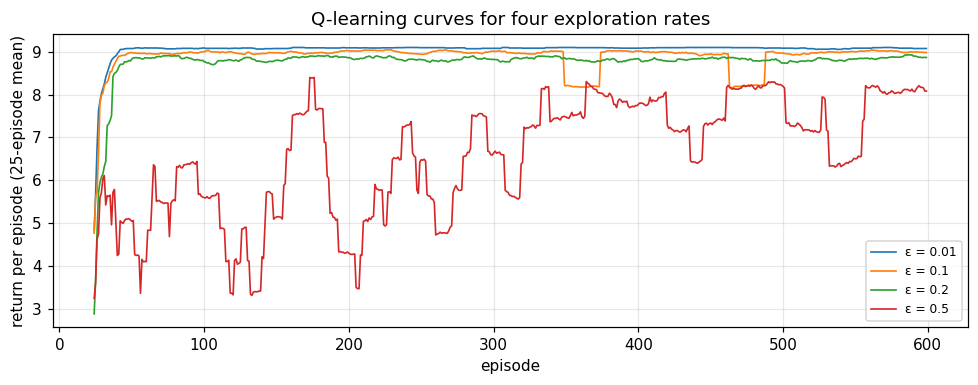

In [4]:
def smooth(v, k=25):
    return np.convolve(v, np.ones(k)/k, mode="valid")

EPS = (0.01, 0.10, 0.20, 0.50)
Qs, table = {}, []
fig, ax = plt.subplots(figsize=(9, 3.6))
for eps in EPS:
    Q, curve = train(eps)
    Qs[eps] = Q
    ax.plot(np.arange(24, EPISODES), smooth(curve), lw=1.1, label=f"ε = {eps}")
    first_goal = int((np.flatnonzero(curve > 0)[0] if np.any(curve > 0) else None))      # first episode that ended at the goal
    table.append({"eps": eps, "mean_last100": float(curve[-100:].mean()), "first_success": first_goal})
    print(f"eps = {eps:4.2f}: mean return over last 100 episodes = {curve[-100:].mean():.2f}, "
          f"first goal reached in episode {first_goal}")
ax.set(xlabel="episode", ylabel="return per episode (25-episode mean)",
       title="Q-learning curves for four exploration rates")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); save(fig, "fig5_1_learning_curves.png"); plt.show()
RESULTS["eps_table"] = table

## 4. Extracting the policy and checking it against value iteration

In [5]:
OPEN = [(r, c) for r in range(H) for c in range(W) if (r, c) not in WALLS and (r, c) not in (GOAL, PIT)]

def value_iteration(gamma=GAMMA, tol=1e-10):
    V = np.zeros((H, W))
    while True:
        Vn = V.copy()
        for s in OPEN:
            Vn[s] = max(r + gamma*V[ns]*(not d) for ns, r, d in (step(s, a) for a in range(4)))
        if np.max(np.abs(Vn - V)) < tol:
            return Vn
        V = Vn

V = value_iteration()
def optimal_actions(s):
    q = [r + GAMMA*V[ns]*(not d) for ns, r, d in (step(s, a) for a in range(4))]
    return {a for a in range(4) if q[a] >= max(q) - 1e-9}

def greedy_path(Q):
    s, path = START, [START]
    for _ in range(50):
        s, _, d = step(s, int(np.argmax(Q[s])))
        path.append(s)
        if d: break
    return path

ARROW = "↑↓←→"
opt_rows = []
for eps in EPS:
    pol = np.argmax(Qs[eps], axis=2)
    wrong = [s for s in OPEN if pol[s] not in optimal_actions(s)]
    path = greedy_path(Qs[eps])
    opt_rows.append({"eps": eps, "states_optimal": len(OPEN) - len(wrong), "states": len(OPEN),
                     "path_steps": len(path) - 1, "reaches_goal": path[-1] == GOAL})
    print(f"eps = {eps:4.2f}: optimal action in {len(OPEN)-len(wrong)}/{len(OPEN)} states; greedy path "
          f"from start = {len(path)-1} steps, ends at {'GOAL' if path[-1] == GOAL else path[-1]}")
# length of the optimal path from value iteration
s, n_opt = START, 0
while s != GOAL:
    s, _, _ = step(s, min(optimal_actions(s))); n_opt += 1
print("optimal path length (value iteration):", n_opt, "steps")
RESULTS["optimality"] = opt_rows
RESULTS["optimal_steps"] = n_opt

eps = 0.01: optimal action in 26/28 states; greedy path from start = 10 steps, ends at GOAL
eps = 0.10: optimal action in 26/28 states; greedy path from start = 10 steps, ends at GOAL
eps = 0.20: optimal action in 28/28 states; greedy path from start = 10 steps, ends at GOAL
eps = 0.50: optimal action in 28/28 states; greedy path from start = 10 steps, ends at GOAL
optimal path length (value iteration): 10 steps


→ → → → → → G
→ ↑ # ↑ # ↑ ↑
↑ ↑ # ↑ # ↑ P
↑ ↑ # ↑ → ↑ ←
↑ → → ↑ → ↑ ←


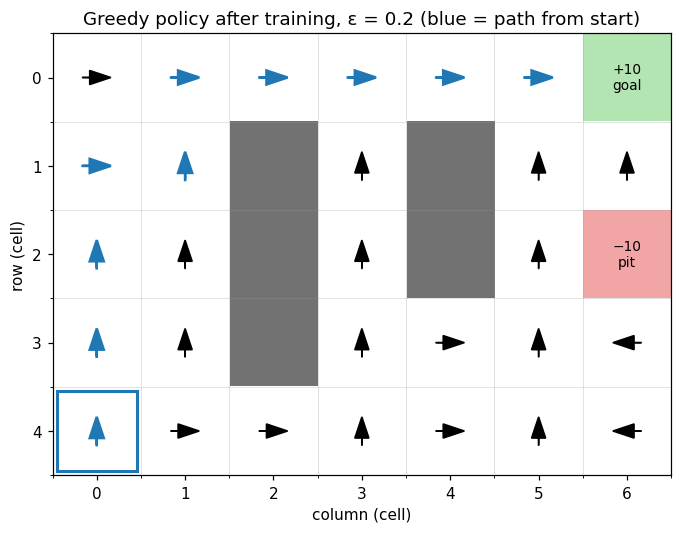

In [6]:
EPS_SHOW = 0.20
pol = np.argmax(Qs[EPS_SHOW], axis=2)
grid_txt = []
for r in range(H):
    row = []
    for c in range(W):
        s = (r, c)
        row.append("#" if s in WALLS else "G" if s == GOAL else "P" if s == PIT else ARROW[pol[s]])
    grid_txt.append(" ".join(row))
print("\n".join(grid_txt))
RESULTS["policy_grid"] = grid_txt

path = greedy_path(Qs[EPS_SHOW])
fig, ax = plt.subplots(figsize=(6.4, 4.8))
img = np.ones((H, W, 3))
for s in WALLS: img[s] = (0.45, 0.45, 0.45)
img[GOAL] = (0.70, 0.90, 0.70); img[PIT] = (0.95, 0.65, 0.65)
ax.imshow(img, extent=(-0.5, W - 0.5, H - 0.5, -0.5))
DXY = {0: (0, -0.32), 1: (0, 0.32), 2: (-0.32, 0), 3: (0.32, 0)}
for s in OPEN:
    dx, dy = DXY[pol[s]]
    on = s in path
    ax.arrow(s[1] - dx/2, s[0] - dy/2, dx, dy, head_width=0.16, length_includes_head=True,
             color="tab:blue" if on else "k", lw=1.6 if on else 1)
ax.text(GOAL[1], GOAL[0], "+10\ngoal", ha="center", va="center", fontsize=9)
ax.text(PIT[1], PIT[0], "−10\npit", ha="center", va="center", fontsize=9)
ax.add_patch(plt.Rectangle((START[1] - 0.45, START[0] - 0.45), 0.9, 0.9, fill=False, lw=2, ec="tab:blue"))
ax.set_xticks(range(W)); ax.set_yticks(range(H))
ax.set_xticks(np.arange(-0.5, W), minor=True); ax.set_yticks(np.arange(-0.5, H), minor=True)
ax.grid(which="minor", color="0.6", lw=0.6); ax.grid(which="major", visible=False)
ax.set(xlabel="column (cell)", ylabel="row (cell)",
       title=f"Greedy policy after training, ε = {EPS_SHOW} (blue = path from start)")
fig.tight_layout(); save(fig, "fig5_2_policy.png"); plt.show()

In [7]:
with open("results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=float)
print("saved results.json and", len(os.listdir("figs")), "figures in figs/")

saved results.json and 2 figures in figs/
